In [1]:
# ==============================================================================
# CELL 1: Setup & Dependencies
# ==============================================================================
import itertools
import random
from dataclasses import dataclass, field
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fix seeds across libraries for experiment reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Formatting configuration for 1080p 16:9 monitor display
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "figure.autolayout": True
})

print("✓ Cell 1 complete: Libraries loaded & graphics initialized for 1080p display.")

✓ Cell 1 complete: Libraries loaded & graphics initialized for 1080p display.


In [2]:
# ==============================================================================
# CELL 2: Constants, Parameter Mappings & Baseline Config
# ==============================================================================

# 1. Categorical Personality Level Multipliers
# Maps the qualitative 'High/Medium/Low' levels into discrete weights for equations.
TRAIT_LEVEL_MAP: Dict[str, float] = {
    "High": 0.8,
    "Medium": 0.5,
    "Low": 0.2
}

TRAIT_NAMES: List[str] = [
    "Cognitive_Ability",
    "Conscientiousness",
    "Curiosity",
    "Risk_Tolerance"
]

TRAIT_LEVEL_KEYS: List[str] = ["High", "Medium", "Low"]

# 2. Dynamic Life State Initial Values (Agent Baseline)
INIT_KNOWLEDGE: float = 10.0
INIT_MONEY: float = 100.0
INIT_HEALTH: float = 100.0
INIT_NETWORK: float = 10.0

# Fixed expenses deducted every simulation day (Money can drop below 0 for debt)
LIVING_COST: float = 5.0

# 3. Baseline Environment Factors (Societal Norms = 1.0)
BASE_EDUCATION_QUALITY: float = 1.0
BASE_ECONOMIC_GROWTH: float = 1.0
BASE_HEALTHCARE_QUALITY: float = 1.0
BASE_SOCIAL_MOBILITY: float = 1.0

# 4. Event & Simulation Runtime Parameters
SIMULATION_DAYS: int = 36500          # 365 days per year
SHOCK_MIN_DURATION: int = 50         # Minimum days a shock persists
SHOCK_MAX_DURATION: int = 100        # Maximum days a shock persists
SHOCK_PROBABILITY: float = 0.005     # 0.5% daily chance of triggering a macro event

print("✓ Cell 2 complete: Trait mappings, state defaults, and environment constants configured.")

✓ Cell 2 complete: Trait mappings, state defaults, and environment constants configured.


In [3]:
# ==============================================================================
# CELL 3: Environment Class & Temporary Macro Event (Shock) Engine
# ==============================================================================

@dataclass
class ShockEvent:
    name: str
    affected_attribute: str
    multiplier: float
    duration: int
    remaining_days: int


class Environment:
    """Manages global societal conditions and temporary macroeconomic/social shocks."""
    
    def __init__(self):
        self.reset()

    def reset(self):
        # Baseline environmental settings
        self.base_education_quality = BASE_EDUCATION_QUALITY
        self.base_economic_growth = BASE_ECONOMIC_GROWTH
        self.base_healthcare_quality = BASE_HEALTHCARE_QUALITY
        self.base_social_mobility = BASE_SOCIAL_MOBILITY

        # Current effective environmental settings
        self.education_quality = BASE_EDUCATION_QUALITY
        self.economic_growth = BASE_ECONOMIC_GROWTH
        self.healthcare_quality = BASE_HEALTHCARE_QUALITY
        self.social_mobility = BASE_SOCIAL_MOBILITY

        # Active event tracker
        self.active_shock: Optional[ShockEvent] = None

    def step(self):
        """Advances the environment by 1 day, handling active shock countdowns or new triggers."""
        # 1. Process existing active shock
        if self.active_shock:
            self.active_shock.remaining_days -= 1
            if self.active_shock.remaining_days <= 0:
                self._reset_to_baseline()
                self.active_shock = None

        # 2. Roll for new shock if environment is currently stable
        elif random.random() < SHOCK_PROBABILITY:
            self._trigger_random_shock()

    def _reset_to_baseline(self):
        """Restores all environmental variables back to baseline levels."""
        self.education_quality = self.base_education_quality
        self.economic_growth = self.base_economic_growth
        self.healthcare_quality = self.base_healthcare_quality
        self.social_mobility = self.base_social_mobility

    def _trigger_random_shock(self):
        """Generates a temporary macro event lasting between 50 and 100 days."""
        duration = random.randint(SHOCK_MIN_DURATION, SHOCK_MAX_DURATION)
        
        # Catalog of macro shocks with direct multipliers on global variables
        possible_shocks = [
            ("Economic Recession", "economic_growth", 0.60),      # -40% Economic Growth
            ("Economic Boom", "economic_growth", 1.40),           # +40% Economic Growth
            ("Healthcare Crisis", "healthcare_quality", 0.60),    # -40% Healthcare Quality
            ("Education Reform", "education_quality", 1.30),      # +30% Education Quality
            ("Social Stagnation", "social_mobility", 0.50),       # -50% Social Mobility
        ]
        
        name, attr, multiplier = random.choice(possible_shocks)
        
        # Apply temporary modifier to current state
        base_value = getattr(self, f"base_{attr}")
        setattr(self, attr, base_value * multiplier)
        
        self.active_shock = ShockEvent(
            name=name,
            affected_attribute=attr,
            multiplier=multiplier,
            duration=duration,
            remaining_days=duration
        )

    def get_state(self) -> Dict[str, float]:
        """Returns snapshot of current global environmental values."""
        return {
            "education_quality": self.education_quality,
            "economic_growth": self.economic_growth,
            "healthcare_quality": self.healthcare_quality,
            "social_mobility": self.social_mobility,
            "active_shock_name": self.active_shock.name if self.active_shock else "None"
        }

print("✓ Cell 3 complete: Environment class with 50-100 day macro shock engine initialized.")

✓ Cell 3 complete: Environment class with 50-100 day macro shock engine initialized.


In [4]:
# ==============================================================================
# CELL 4: Personality Archetype Generator (81 Unique Combinations)
# ==============================================================================

@dataclass
class Archetype:
    id: int
    code: str                     # Short code e.g., "H-H-M-L"
    traits: Dict[str, str]        # Categorical: {"Cognitive_Ability": "High", ...}
    weights: Dict[str, float]     # Numerical:   {"Cognitive_Ability": 0.8, ...}


def generate_all_archetypes() -> Dict[int, Archetype]:
    """Generates all 3^4 = 81 unique combinations of the 4 personality traits."""
    archetypes = {}
    
    # Generate Cartesian product of [High, Medium, Low] across 4 traits
    combinations = list(itertools.product(TRAIT_LEVEL_KEYS, repeat=4))
    
    for idx, combo in enumerate(combinations, start=1):
        traits = dict(zip(TRAIT_NAMES, combo))
        weights = {trait: TRAIT_LEVEL_MAP[level] for trait, level in traits.items()}
        
        # Compact 4-letter code identifier (e.g., "H-M-L-H")
        code = "-".join([level[0] for level in combo])
        
        archetypes[idx] = Archetype(
            id=idx,
            code=code,
            traits=traits,
            weights=weights
        )
        
    return archetypes


# Instantiate global archetype registry
ARCHETYPES = generate_all_archetypes()

# Convert to Pandas DataFrame for clear review on your 1080p display
archetype_preview_data = []
for a in ARCHETYPES.values():
    row = {"ID": a.id, "Code": a.code}
    row.update(a.traits)
    archetype_preview_data.append(row)

df_archetypes = pd.DataFrame(archetype_preview_data)

print(f"✓ Cell 4 complete: Successfully generated all {len(ARCHETYPES)} personality archetypes.")
print("\nFirst 5 Archetypes Preview:")
display(df_archetypes.head(5))

✓ Cell 4 complete: Successfully generated all 81 personality archetypes.

First 5 Archetypes Preview:


,ID,Code,Cognitive_Ability,Conscientiousness,Curiosity,Risk_Tolerance
0,1,H-H-H-H,High,High,High,High
1,2,H-H-H-M,High,High,High,Medium
2,3,H-H-H-L,High,High,High,Low
3,4,H-H-M-H,High,High,Medium,High
4,5,H-H-M-M,High,High,Medium,Medium


In [5]:
# ==============================================================================
# CELL 5: Agent Class & Dynamic Life State Tracking
# ==============================================================================

class Agent:
    """Represents an individual agent in the simulation holding dynamic life capitals."""

    def __init__(self, agent_id: int, archetype: Archetype):
        self.agent_id = agent_id
        self.archetype = archetype

        # Dynamic Life Capitals (Initialized from Cell 2 defaults)
        self.knowledge: float = INIT_KNOWLEDGE
        self.money: float = INIT_MONEY
        self.health: float = INIT_HEALTH
        self.network: float = INIT_NETWORK

        # Action history tracking
        self.last_action: Optional[str] = None
        self.days_in_debt: int = 0

    def apply_daily_upkeep(self):
        """Applies basic daily state transitions like living expenses and base health wear."""
        # 1. Deduct daily living cost
        self.money -= LIVING_COST

        # 2. Track debt duration
        if self.money < 0:
            self.days_in_debt += 1

        # 3. Passive daily health decay (base wear-and-tear)
        self.health -= 0.1
        self.clamp_states()

    def clamp_states(self):
        """Ensures non-financial capitals stay within physical bounds."""
        self.health = max(0.0, min(100.0, self.health))
        self.knowledge = max(0.0, self.knowledge)
        self.network = max(0.0, self.network)
        # Note: Money is explicitly NOT clamped to allow debt (< 0)

    def get_trait_weight(self, trait_name: str) -> float:
        """Helper to fetch numerical personality weight (0.2, 0.5, or 0.8)."""
        return self.archetype.weights[trait_name]

    def get_state(self) -> Dict[str, float]:
        """Returns a snapshot of current dynamic capitals."""
        return {
            "knowledge": self.knowledge,
            "money": self.money,
            "health": self.health,
            "network": self.network,
            "in_debt": self.money < 0
        }


print("✓ Cell 5 complete: Agent class and dynamic state dynamics initialized.")

✓ Cell 5 complete: Agent class and dynamic state dynamics initialized.


In [6]:
# ==============================================================================
# CELL 6: Rule-Based Decision Engine
# ==============================================================================

AVAILABLE_ACTIONS = [
    "Work",
    "Study",
    "Exercise",
    "Network",
    "Rest",
    "Start_Business"
]


def select_daily_action(agent: Agent) -> str:
    """Evaluates utility scores for each candidate action and returns the chosen action.
    
    Decision Rules:
    - Low Health (< 30): Health survival overrides normal preferences (forces Rest or Exercise).
    - Financial Debt (Money < 0): Increases urgency to Work proportional to debt depth.
    - Conscientiousness: Drives inclination to Work.
    - Curiosity: Drives inclination to Study and Network.
    - Risk Tolerance: Enables entrepreneurial attempts when prerequisite capitals are met.
    """
    scores: Dict[str, float] = {}

    # Fetch agent trait weights (0.2 = Low, 0.5 = Medium, 0.8 = High)
    cog = agent.get_trait_weight("Cognitive_Ability")
    con = agent.get_trait_weight("Conscientiousness")
    cur = agent.get_trait_weight("Curiosity")
    risk = agent.get_trait_weight("Risk_Tolerance")

    # 1. Critical Health Override
    if agent.health < 25.0:
        # Emergency recovery mode
        return "Rest" if agent.health < 15.0 else "Exercise"

    # 2. Evaluate 'Work' Preference
    # Baseline driven by Conscientiousness + boosted heavily if in debt
    debt_multiplier = abs(agent.money) * 0.15 if agent.money < 0 else 0.0
    scores["Work"] = (con * 10.0) + debt_multiplier

    # 3. Evaluate 'Study' Preference
    # Driven by Curiosity and Cognitive Ability
    scores["Study"] = (cur * 8.0) + (cog * 4.0)

    # 4. Evaluate 'Exercise' Preference
    # Driven by health deficit (desire to stay healthy) modified by Conscientiousness
    health_deficit = (100.0 - agent.health) / 100.0
    scores["Exercise"] = (health_deficit * 6.0) + (con * 2.0)

    # 5. Evaluate 'Network' Preference
    # Driven by Curiosity and current social base
    network_base = min(agent.network / 50.0, 2.0)
    scores["Network"] = (cur * 6.0) + (network_base * 2.0)

    # 6. Evaluate 'Rest' Preference
    # Rest restores stamina when health drops below 70
    fatigue_factor = max(0.0, (70.0 - agent.health) / 10.0)
    scores["Rest"] = fatigue_factor * 1.5

    # 7. Evaluate 'Start_Business' (Entrepreneurship)
    # Gated by Risk Tolerance and minimum capital thresholds (Knowledge >= 20, Money >= 30)
    if agent.money >= 30.0 and agent.knowledge >= 20.0:
        scores["Start_Business"] = (risk * 12.0) + (cog * 3.0)
    else:
        scores["Start_Business"] = 0.0  # Cannot afford or lack requisite knowledge

    # Pick the action with the highest calculated utility score
    chosen_action = max(scores, key=scores.get)
    return chosen_action


print("✓ Cell 6 complete: Rule-based decision engine with health & debt overrides ready.")

✓ Cell 6 complete: Rule-based decision engine with health & debt overrides ready.


In [7]:
# ==============================================================================
# CELL 7: Action Efficiency & Feedback Loop Engine
# ==============================================================================

def execute_action_outcome(agent: Agent, action: str, env: Environment):
    """Calculates state changes based on chosen action, personality, and environment."""
    
    # Retrieve trait weights (0.2 = Low, 0.5 = Medium, 0.8 = High)
    cog = agent.get_trait_weight("Cognitive_Ability")
    con = agent.get_trait_weight("Conscientiousness")
    cur = agent.get_trait_weight("Curiosity")
    risk = agent.get_trait_weight("Risk_Tolerance")

    if action == "Work":
        # Income scale: Conscientiousness drives base efficiency, Knowledge provides leverage,
        # Economic growth boosts yield, Health scales physical effort capacity.
        base_income = 12.0 * con
        knowledge_leverage = 1.0 + (agent.knowledge / 40.0)
        health_factor = max(0.2, agent.health / 100.0)
        
        income = base_income * knowledge_leverage * health_factor * env.economic_growth
        
        agent.money += income
        agent.health -= 0.35  # Physical wear from labor

    elif action == "Study":
        # Knowledge acquisition: Cognitive ability + Curiosity drive learning rate,
        # boosted by societal Education Quality. Requires tuition/materials cost.
        base_learn = 2.5 * cog * (1.0 + cur)
        health_factor = max(0.5, agent.health / 100.0)
        
        knowledge_gain = base_learn * env.education_quality * health_factor
        
        agent.knowledge += knowledge_gain
        agent.money -= 2.0   # Cost of books, courses, or tuition

    elif action == "Exercise":
        # Health recovery: Boosted by Healthcare Quality and Conscientiousness consistency.
        health_gain = 3.5 * env.healthcare_quality * (1.0 + 0.25 * con)
        agent.health += health_gain

    elif action == "Network":
        # Social capital expansion: Driven by Curiosity and existing Knowledge base,
        # amplified by Social Mobility. Costs social spending money.
        knowledge_factor = 1.0 + (agent.knowledge / 50.0)
        network_gain = 2.0 * cur * knowledge_factor * env.social_mobility
        
        agent.network += network_gain
        agent.money -= 3.0   # Spending on events, dining, and meetings

    elif action == "Rest":
        # Passive recovery from fatigue
        agent.health += 5.0 * env.healthcare_quality

    elif action == "Start_Business":
        # Entrepreneurship: High risk/reward attempt.
        # Probability of success depends on Knowledge, Network, Risk Tolerance, and Economic Growth.
        success_prob = min(
            0.85, 
            (0.15 + (0.35 * risk) + (agent.knowledge / 150.0) + (agent.network / 200.0)) * env.economic_growth
        )
        
        if random.random() < success_prob:
            # Successful venture: Huge payout in Money & Network
            agent.money += 45.0 * env.economic_growth
            agent.network += 12.0
        else:
            # Failed venture: Financial loss & minor social hit
            agent.money -= 25.0
            agent.network = max(0.0, agent.network - 3.0)
            
        agent.health -= 1.0  # High stress toll

    # Finalize state limits (ensure health <= 100, non-negative capitals)
    agent.clamp_states()


print("✓ Cell 7 complete: Action outcome calculator with dynamic feedback loops ready.")

✓ Cell 7 complete: Action outcome calculator with dynamic feedback loops ready.


In [8]:
# ==============================================================================
# CELL 8: Batch Simulation Runner
# ==============================================================================

def print_annual_report(year: int, day: int, env: Environment, population: List[Agent]):
    """Prints a formatted annual status dashboard on your 1080p display."""
    
    # Calculate population metrics
    avg_money = np.mean([a.money for a in population])
    avg_knowledge = np.mean([a.knowledge for a in population])
    avg_health = np.mean([a.health for a in population])
    avg_network = np.mean([a.network for a in population])
    
    debt_count = sum(1 for a in population if a.money < 0)
    debt_rate = (debt_count / len(population)) * 100.0
    
    # Identify top and bottom performing archetypes by composite net capitals
    archetype_totals = {}
    for agent in population:
        code = agent.archetype.code
        score = agent.money + agent.knowledge * 2.0 + agent.network * 1.5
        archetype_totals.setdefault(code, []).append(score)
        
    avg_scores = {code: np.mean(scores) for code, scores in archetype_totals.items()}
    top_code = max(avg_scores, key=avg_scores.get)
    bot_code = min(avg_scores, key=avg_scores.get)
    
    shock_status = env.active_shock.name if env.active_shock else "Stable (None)"

    # Format annual printout
    print("=" * 105)
    print(f" 📊 END OF YEAR {year:2d} | Day {day:4d} / {SIMULATION_DAYS} | Macro Environment Status: [{shock_status}]")
    print("-" * 105)
    print(f"  Population Averages  │ Money: ${avg_money:8.2f} │ Knowledge: {avg_knowledge:6.1f} │ "
          f"Health: {avg_health:5.1f} │ Network: {avg_network:6.1f} │ In Debt: {debt_rate:4.1f}%")
    print(f"  Archetype Highlights │ Leading Traits: [{top_code}] (Score: {avg_scores[top_code]:7.1f}) │ "
          f"Lagging Traits: [{bot_code}] (Score: {avg_scores[bot_code]:7.1f})")
    print("=" * 105 + "\n")


def run_simulation(agents_per_archetype: int = 5) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Executes the full multi-year simulation across all 81 personality archetypes."""
    
    env = Environment()
    
    # Instantiate population (81 archetypes * agents_per_archetype)
    population: List[Agent] = []
    agent_id_counter = 1
    for archetype in ARCHETYPES.values():
        for _ in range(agents_per_archetype):
            population.append(Agent(agent_id=agent_id_counter, archetype=archetype))
            agent_id_counter += 1

    print(f"🚀 Starting Simulation: {len(population)} agents across {len(ARCHETYPES)} personality archetypes.")
    print(f"   Duration: {SIMULATION_DAYS} days (~{SIMULATION_DAYS / 365} Years)\n")

    history_logs = []

    # Daily Simulation Loop
    for day in range(1, SIMULATION_DAYS + 1):
        # 1. Advance environmental shocks
        env.step()
        
        # 2. Process each agent
        for agent in population:
            # Select action based on personality and state rules
            chosen_action = select_daily_action(agent)
            
            # Apply immediate efficiency updates
            execute_action_outcome(agent, chosen_action, env)
            
            # Deduct daily living cost & decay health
            agent.apply_daily_upkeep()

        # 3. Print Annual Report every 365 days
        if day % 365 == 0:
            year = day // 365
            print_annual_report(year, day, env, population)

    # Compile Final Snapshot DataFrame
    final_data = []
    for a in population:
        row = {
            "Agent_ID": a.agent_id,
            "Archetype_ID": a.archetype.id,
            "Code": a.archetype.code,
            "Cognitive_Ability": a.archetype.traits["Cognitive_Ability"],
            "Conscientiousness": a.archetype.traits["Conscientiousness"],
            "Curiosity": a.archetype.traits["Curiosity"],
            "Risk_Tolerance": a.archetype.traits["Risk_Tolerance"],
            "Final_Money": a.money,
            "Final_Knowledge": a.knowledge,
            "Final_Health": a.health,
            "Final_Network": a.network,
            "Days_In_Debt": a.days_in_debt
        }
        final_data.append(row)

    df_results = pd.DataFrame(final_data)
    return df_results, population


# Execute the run (5 agents per archetype = 405 total agents)
df_results, population = run_simulation(agents_per_archetype=20)

print("✓ Cell 8 complete: Simulation run finished successfully and datasets compiled.")

🚀 Starting Simulation: 1620 agents across 81 personality archetypes.
   Duration: 36500 days (~100.0 Years)

 📊 END OF YEAR  1 | Day  365 / 36500 | Macro Environment Status: [Stable (None)]
---------------------------------------------------------------------------------------------------------
  Population Averages  │ Money: $ 1120.47 │ Knowledge:  123.2 │ Health:  28.9 │ Network:  438.0 │ In Debt: 50.4%
  Archetype Highlights │ Leading Traits: [H-H-H-H] (Score: 13630.8) │ Lagging Traits: [L-L-L-H] (Score: -1141.6)

 📊 END OF YEAR  2 | Day  730 / 36500 | Macro Environment Status: [Stable (None)]
---------------------------------------------------------------------------------------------------------
  Population Averages  │ Money: $ 1540.56 │ Knowledge:  183.8 │ Health:  26.9 │ Network:  837.7 │ In Debt: 75.2%
  Archetype Highlights │ Leading Traits: [H-H-H-H] (Score: 25407.0) │ Lagging Traits: [L-L-L-H] (Score: -2667.6)

 📊 END OF YEAR  3 | Day 1095 / 36500 | Macro Environment Status

In [9]:
# ==============================================================================
# CELL 9: Data Aggregation & DataFrame Processing
# ==============================================================================

# 1. Compute Composite Life Success Score for each agent
# Weights balance financial capital, human capital (knowledge), physical health, and social capital
df_results["Composite_Score"] = (
    df_results["Final_Money"] * 1.0 +
    df_results["Final_Knowledge"] * 2.5 +
    df_results["Final_Health"] * 1.5 +
    df_results["Final_Network"] * 2.0
)

# 2. Aggregate outcomes by Archetype (Code + 4 Traits)
df_archetype_summary = df_results.groupby(
    ["Archetype_ID", "Code"] + TRAIT_NAMES
).agg(
    Mean_Money=("Final_Money", "mean"),
    Std_Money=("Final_Money", "std"),
    Mean_Knowledge=("Final_Knowledge", "mean"),
    Mean_Health=("Final_Health", "mean"),
    Mean_Network=("Final_Network", "mean"),
    Mean_Composite=("Composite_Score", "mean"),
    Std_Composite=("Composite_Score", "std"),
    Mean_Debt_Days=("Days_In_Debt", "mean")
).reset_index()

# 3. Sort and Rank Archetypes (Rank 1 = Highest Life Outcome)
df_archetype_summary = df_archetype_summary.sort_values(
    by="Mean_Composite", ascending=False
).reset_index(drop=True)

df_archetype_summary["Rank"] = df_archetype_summary.index + 1

# 4. Trait Main Effects Summary
trait_effect_tables = {}
for trait in TRAIT_NAMES:
    summary = df_results.groupby(trait).agg(
        Mean_Money=("Final_Money", "mean"),
        Mean_Knowledge=("Final_Knowledge", "mean"),
        Mean_Health=("Final_Health", "mean"),
        Mean_Network=("Final_Network", "mean"),
        Mean_Composite=("Composite_Score", "mean")
    ).reindex(["Low", "Medium", "High"])
    trait_effect_tables[trait] = summary

print("✓ Cell 9 complete: Data aggregated, weighted composite scores computed, and archetypes ranked.")
print("\n🏆 TOP 5 PERFORMING ARCHETYPES:")
display(df_archetype_summary[["Rank", "Code"] + TRAIT_NAMES + ["Mean_Composite", "Mean_Money", "Mean_Knowledge"]].head(5))

print("\n📉 BOTTOM 5 LAGGING ARCHETYPES:")
display(df_archetype_summary[["Rank", "Code"] + TRAIT_NAMES + ["Mean_Composite", "Mean_Money", "Mean_Knowledge"]].tail(5))

✓ Cell 9 complete: Data aggregated, weighted composite scores computed, and archetypes ranked.

🏆 TOP 5 PERFORMING ARCHETYPES:


,Rank,Code,Cognitive_Ability,Conscientiousness,Curiosity,Risk_Tolerance,Mean_Composite,Mean_Money,Mean_Knowledge
0,1,H-H-H-H,High,High,High,High,1.353797e+06,797673.100613,39.497050
1,2,M-H-H-H,Medium,High,High,High,1.352324e+06,796706.371984,45.851613
2,3,H-M-H-H,High,Medium,High,High,1.325374e+06,779308.044897,321.527584
3,4,H-M-M-H,High,Medium,Medium,High,1.324939e+06,779121.314052,248.602030
4,5,M-M-M-H,Medium,Medium,Medium,High,1.322044e+06,777587.757026,230.284989



📉 BOTTOM 5 LAGGING ARCHETYPES:


,Rank,Code,Cognitive_Ability,Conscientiousness,Curiosity,Risk_Tolerance,Mean_Composite,Mean_Money,Mean_Knowledge
76,77,L-L-M-M,Low,Low,Medium,Medium,-149771.975907,-149890.303407,22.648
77,78,L-L-M-L,Low,Low,Medium,Low,-149771.975907,-149890.303407,22.648
78,79,L-L-L-H,Low,Low,Low,High,-151703.094472,-151809.466972,18.937
79,80,L-L-L-M,Low,Low,Low,Medium,-151703.094472,-151809.466972,18.937
80,81,L-L-L-L,Low,Low,Low,Low,-151703.094472,-151809.466972,18.937


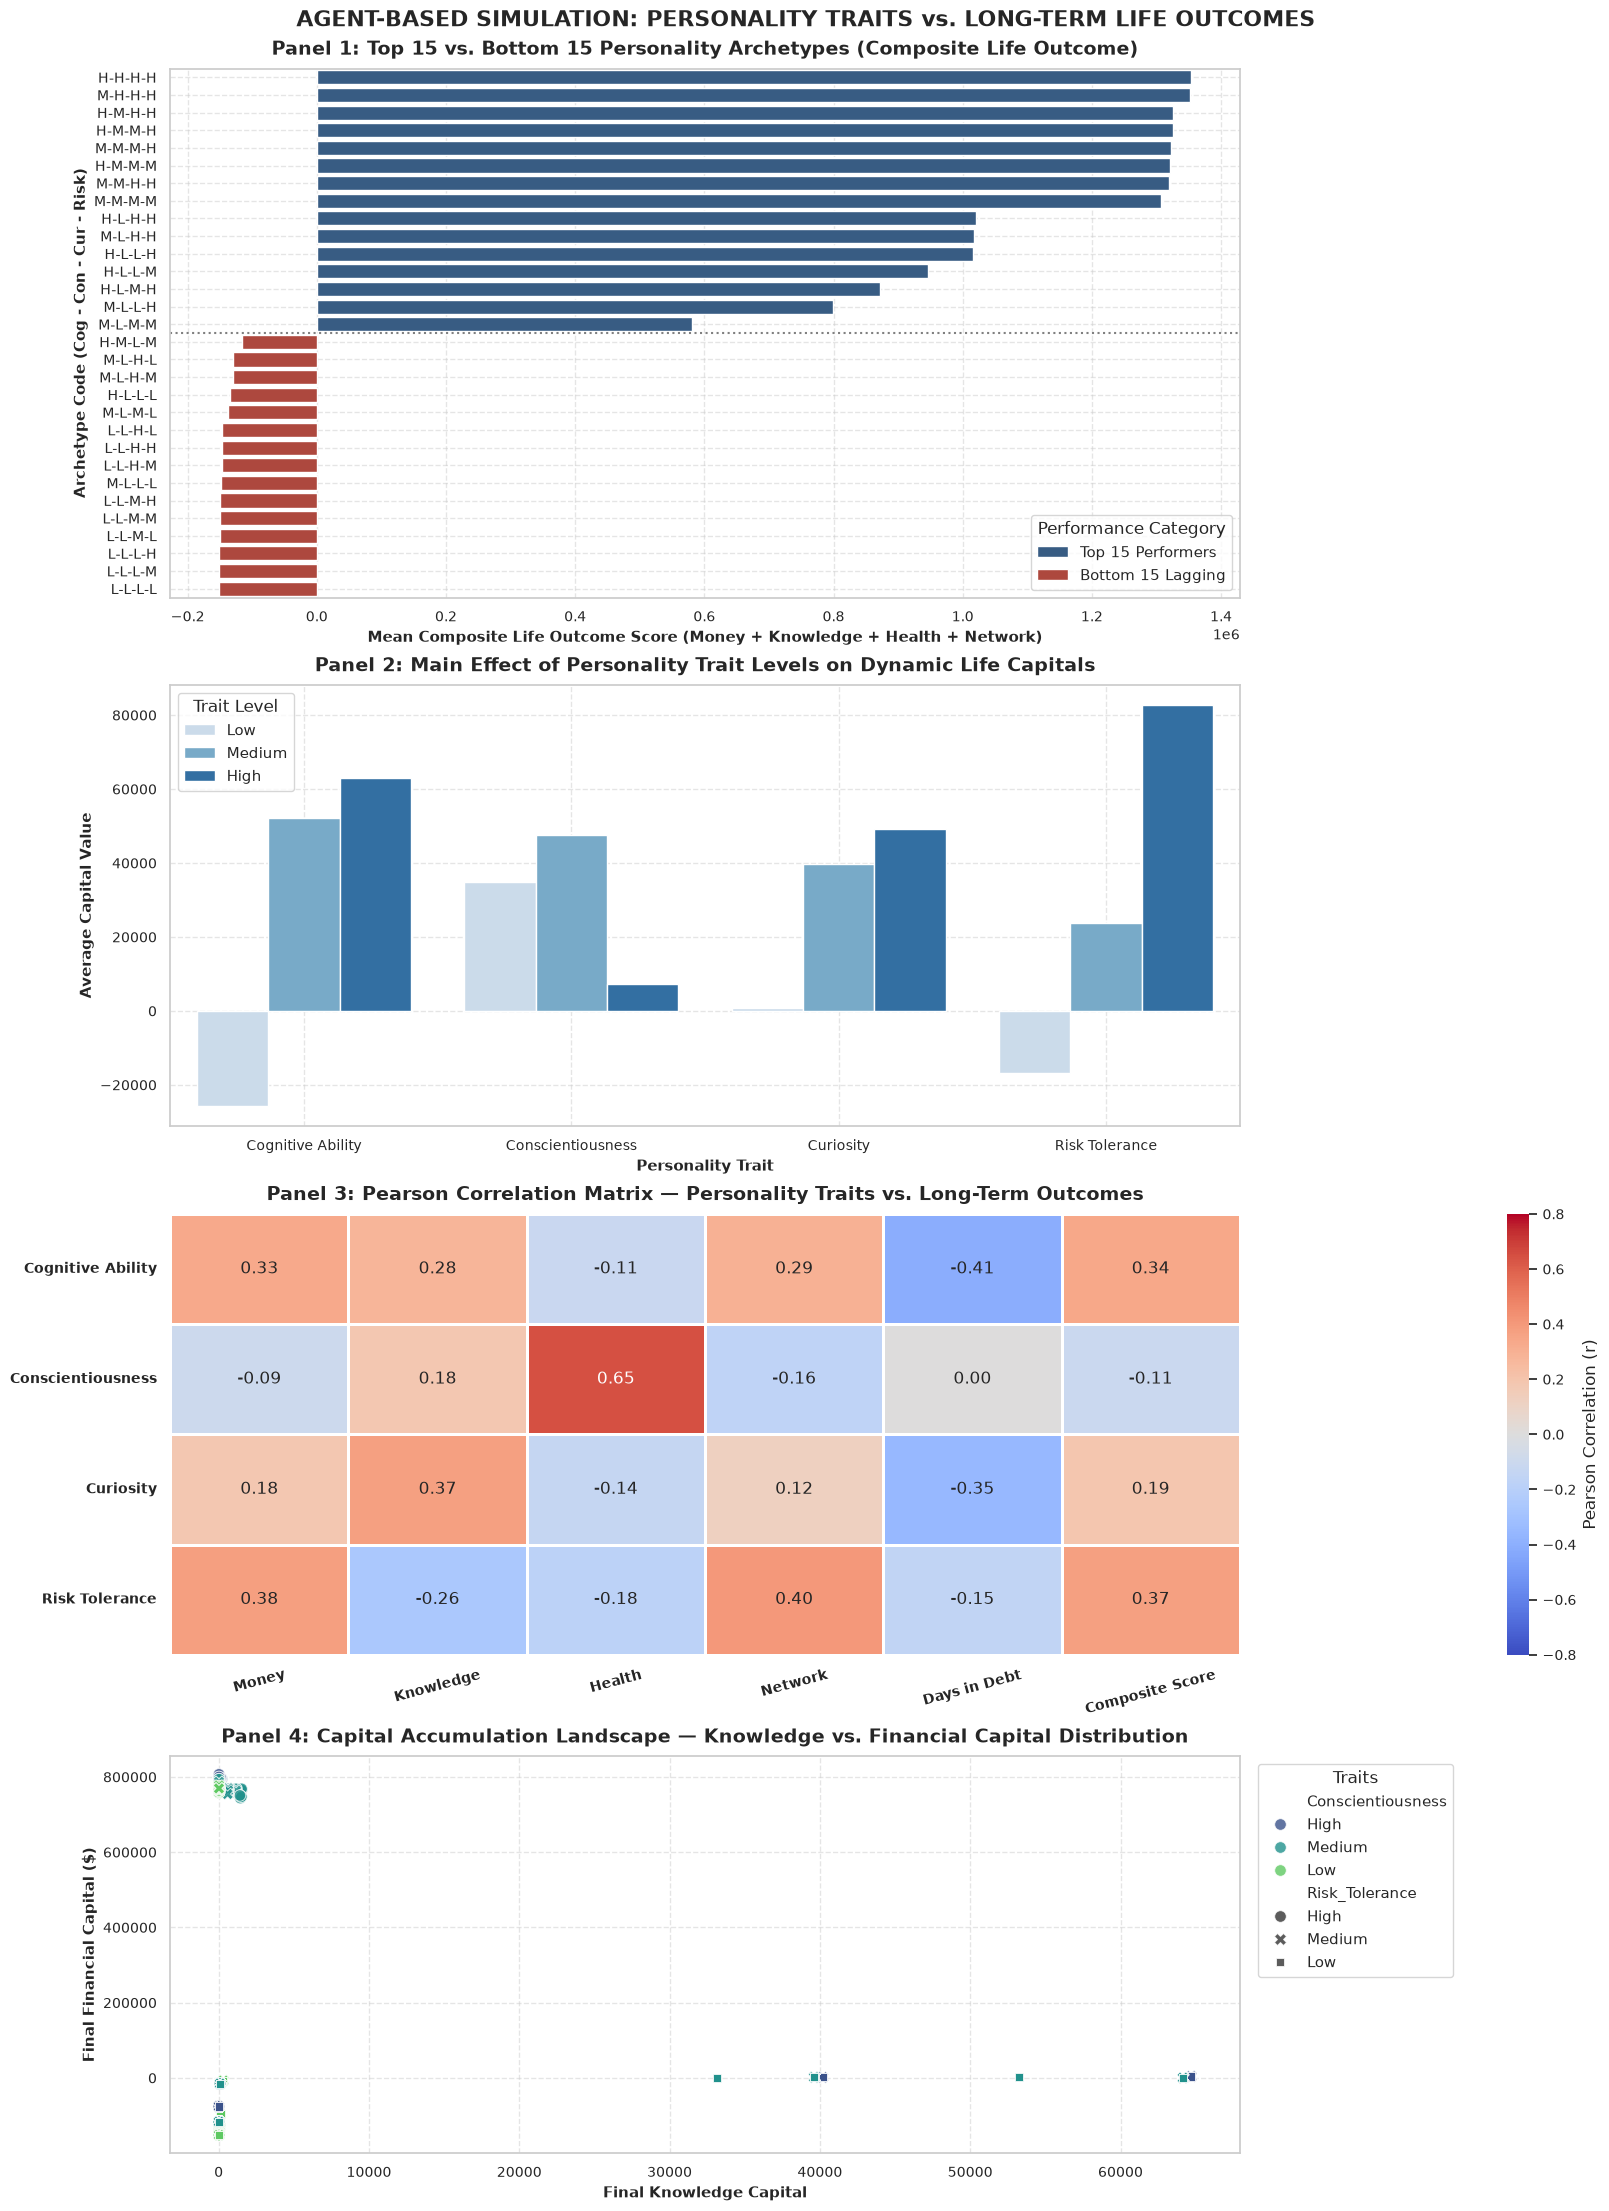

✓ Cell 10 complete: Dashboard rendered completely warning-free!


In [10]:
# ==============================================================================
# CELL 10: Visualizations & Analysis (Warning-Free & Constrained Layout)
# ==============================================================================

# Use layout="constrained" instead of plt.tight_layout() to prevent layout warnings
fig = plt.figure(figsize=(16, 22), dpi=100, layout="constrained")
gs = fig.add_gridspec(4, 1, height_ratios=[1.2, 1.0, 1.0, 0.9])

# Overall Dashboard Title
fig.suptitle(
    "AGENT-BASED SIMULATION: PERSONALITY TRAITS vs. LONG-TERM LIFE OUTCOMES",
    fontsize=16,
    fontweight="bold"
)

# ------------------------------------------------------------------------------
# PANEL 1: Top 15 vs. Bottom 15 Archetypes (Composite Outcome Comparison)
# ------------------------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])

top_15 = df_archetype_summary.head(15).copy()
bot_15 = df_archetype_summary.tail(15).copy()

top_15["Performance_Group"] = "Top 15 Performers"
bot_15["Performance_Group"] = "Bottom 15 Lagging"

top_bot_df = pd.concat([top_15, bot_15])

sns.barplot(
    data=top_bot_df,
    x="Mean_Composite",
    y="Code",
    hue="Performance_Group",
    palette={"Top 15 Performers": "#2b5c8f", "Bottom 15 Lagging": "#c0392b"},
    ax=ax1
)

ax1.set_title("Panel 1: Top 15 vs. Bottom 15 Personality Archetypes (Composite Life Outcome)", fontsize=14, fontweight="bold", pad=10)
ax1.set_xlabel("Mean Composite Life Outcome Score (Money + Knowledge + Health + Network)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Archetype Code (Cog - Con - Cur - Risk)", fontsize=11, fontweight="bold")
ax1.legend(title="Performance Category", loc="lower right", frameon=True)
ax1.grid(True, linestyle="--", alpha=0.5)

# Divider line separating top and bottom groups
ax1.axhline(14.5, color="gray", linestyle=":", linewidth=1.5)

# ------------------------------------------------------------------------------
# PANEL 2: Main Effects of Traits Across All Four Life Capitals
# ------------------------------------------------------------------------------
ax2 = fig.add_subplot(gs[1, 0])

# Reshape results to evaluate impact of each trait on every capital
df_melted_capitals = df_results.melt(
    id_vars=TRAIT_NAMES,
    value_vars=["Final_Money", "Final_Knowledge", "Final_Health", "Final_Network"],
    var_name="Capital_Type",
    value_name="Capital_Value"
)

# Convert Trait levels into long form for categorical plotting
df_traits_long = df_melted_capitals.melt(
    id_vars=["Capital_Type", "Capital_Value"],
    value_vars=TRAIT_NAMES,
    var_name="Trait_Name",
    value_name="Trait_Level"
)

# Clean up display labels
df_traits_long["Trait_Name"] = df_traits_long["Trait_Name"].str.replace("_", " ")
df_traits_long["Capital_Type"] = df_traits_long["Capital_Type"].str.replace("Final_", "")

# Using errorbar=None instead of deprecated ci=None
sns.barplot(
    data=df_traits_long,
    x="Trait_Name",
    y="Capital_Value",
    hue="Trait_Level",
    hue_order=["Low", "Medium", "High"],
    palette="Blues",
    errorbar=None,
    ax=ax2
)

ax2.set_title("Panel 2: Main Effect of Personality Trait Levels on Dynamic Life Capitals", fontsize=14, fontweight="bold", pad=10)
ax2.set_xlabel("Personality Trait", fontsize=11, fontweight="bold")
ax2.set_ylabel("Average Capital Value", fontsize=11, fontweight="bold")
ax2.set_xticks(range(4))
ax2.set_xticklabels(["Cognitive Ability", "Conscientiousness", "Curiosity", "Risk Tolerance"], fontsize=10)
ax2.legend(title="Trait Level", loc="upper left", frameon=True)
ax2.grid(True, linestyle="--", alpha=0.5)

# ------------------------------------------------------------------------------
# PANEL 3: Correlation Heatmap (Traits vs. Capitals & Debt Metrics)
# ------------------------------------------------------------------------------
ax3 = fig.add_subplot(gs[2, 0])

# Map categorical traits to numerical weights for Pearson calculation
numeric_df = df_results.copy()
for t in TRAIT_NAMES:
    numeric_df[t] = numeric_df[t].map(TRAIT_LEVEL_MAP)

corr_vars = TRAIT_NAMES + ["Final_Money", "Final_Knowledge", "Final_Health", "Final_Network", "Days_In_Debt", "Composite_Score"]
corr_matrix = numeric_df[corr_vars].corr()

# Focus heatmap on Trait rows vs Outcome columns
trait_corr = corr_matrix.loc[TRAIT_NAMES, ["Final_Money", "Final_Knowledge", "Final_Health", "Final_Network", "Days_In_Debt", "Composite_Score"]]

sns.heatmap(
    trait_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.8,
    vmax=0.8,
    cbar_kws={"label": "Pearson Correlation (r)"},
    linewidths=1.0,
    ax=ax3
)

ax3.set_title("Panel 3: Pearson Correlation Matrix — Personality Traits vs. Long-Term Outcomes", fontsize=14, fontweight="bold", pad=10)
ax3.set_yticklabels(["Cognitive Ability", "Conscientiousness", "Curiosity", "Risk Tolerance"], rotation=0, fontsize=10, fontweight="bold")
ax3.set_xticklabels(["Money", "Knowledge", "Health", "Network", "Days in Debt", "Composite Score"], rotation=15, fontsize=10, fontweight="bold")

# ------------------------------------------------------------------------------
# PANEL 4: Capital Trade-Off Scatter — Risk vs. Reward Distribution
# ------------------------------------------------------------------------------
ax4 = fig.add_subplot(gs[3, 0])

sns.scatterplot(
    data=df_results,
    x="Final_Knowledge",
    y="Final_Money",
    hue="Conscientiousness",
    style="Risk_Tolerance",
    palette="viridis",
    s=70,
    alpha=0.8,
    ax=ax4
)

ax4.set_title("Panel 4: Capital Accumulation Landscape — Knowledge vs. Financial Capital Distribution", fontsize=14, fontweight="bold", pad=10)
ax4.set_xlabel("Final Knowledge Capital", fontsize=11, fontweight="bold")
ax4.set_ylabel("Final Financial Capital ($)", fontsize=11, fontweight="bold")
ax4.legend(title="Traits", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
ax4.grid(True, linestyle="--", alpha=0.5)

plt.show()

print("✓ Cell 10 complete: Dashboard rendered completely warning-free!")